# HuggingFace Model Test — Bore / Needle Tip Detection
Test pretrained models as replacements or upgrades for the BoreCNN fallback.

**Environment:** run in `ml311` (has torch + transformers)
```
conda activate ml311
pip install transformers timm
jupyter notebook hf_model_test.ipynb
```

In [ ]:
# ===========================================================
#  CONFIG — edit here, then Kernel > Restart & Run All
# ===========================================================
config = {
    # --- Identity ---
    "name":       "run_005_xy_cam_3x",
    "note":       "356 labels, xy_cam 3x zoom dataset only, 400px crop",

    # --- Model ---
    "model":      "facebook/dinov2-small",
    # Dataset paths are relative to datasets/ root.
    # xy_cam data lives under datasets/xy_cam/, yz_cam under datasets/yz_cam/
    "datasets":   ["xy_cam/xy_cam_3x"],

    # --- Crop window centered on labeled bore position ---
    # Why crop instead of feeding the full frame:
    #   1. ViT attention is O(n²) in patches; full frame @patch14 = ~4600 patches
    #      vs 256 at 224px — 328x more compute, likely OOM.
    #   2. dinov2-small was pretrained at 224px; larger inputs require interpolating
    #      positional embeddings and degrade the frozen features we rely on.
    # Crop also matches inference: geometric detector already crops to the cap region.
    "crop_size":  400,   # px square centered on bore

    # --- Training ---
    "epochs":     60,
    "lr":         1e-4,
    "batch_size": 8,
    "val_split":  0.15,
}

import pprint; pprint.pprint(config)

In [9]:
import os, sys
import numpy as np
import torch
import torch.nn as nn
from PIL import Image

# Fix Avast TLS interception — patch certifi before any HTTPS calls
_cert = os.path.expanduser("~/.certs/ca-bundle.pem")
if os.path.exists(_cert):
    import certifi
    certifi.where = lambda: _cert
    os.environ["REQUESTS_CA_BUNDLE"] = _cert
    os.environ["CURL_CA_BUNDLE"]     = _cert
    os.environ["SSL_CERT_FILE"]      = _cert

BASE   = os.path.dirname(os.path.abspath('__file__')) if '__file__' in dir() else os.getcwd()
sys.path.insert(0, BASE)

print('torch:',  torch.__version__)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

torch: 2.6.0+cu124
device: cuda


## 1. Load DINOv2-small from HuggingFace
Freezes the backbone — only a small regression head is trainable.

In [10]:
from transformers import AutoModel, AutoImageProcessor

MODEL_ID  = config["model"]
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
backbone  = AutoModel.from_pretrained(MODEL_ID).to(DEVICE)
backbone.eval()
for p in backbone.parameters():
    p.requires_grad_(False)

FEAT_DIM = backbone.config.hidden_size
print(f'Backbone: {MODEL_ID}  |  feat_dim={FEAT_DIM}  |  params={sum(p.numel() for p in backbone.parameters())/1e6:.1f}M')

Backbone: facebook/dinov2-small  |  feat_dim=384  |  params=22.1M


## 2. Regression head
Two outputs: (bore_x_norm, bore_y_norm) in [0, 1] relative to the crop.

In [11]:
class BoreHead(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128), nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 2),
            nn.Sigmoid(),
        )
    def forward(self, x): return self.net(x)

head = BoreHead(FEAT_DIM).to(DEVICE)
trainable = sum(p.numel() for p in head.parameters())
print(f'Head trainable params: {trainable:,}  (backbone frozen)')

Head trainable params: 49,538  (backbone frozen)


## 4. Quick fine-tuning loop on labeled frames
Trains only the regression head (backbone stays frozen) on your `cam1_z3.75x` labeled frames.
DINOv2's frozen features are strong enough that ~50 labels typically gets to <2px MAE — 100 frames is plenty.

In [12]:
import random
from dataset import BoreDataset
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

# Train: color jitter helps with small-dataset overfitting.
# Horizontal flip is intentionally NOT here — it's applied inside BoreDataset
# so the bore_x target gets mirrored too (torchvision flip can't update the label).
tf_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Val: no augmentation, no jitter — fixed crop so metric is comparable run-to-run
tf_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

_kwargs = dict(root=os.path.join(BASE, "datasets"), datasets=config["datasets"],
               crop_size=config.get("crop_size"))

# Probe length first so the split works for any dataset size
_probe = BoreDataset(**_kwargs)
indices = list(range(len(_probe)))
random.shuffle(indices)
n_val = max(1, int(len(indices) * config["val_split"]))
train_idx, val_idx = indices[n_val:], indices[:n_val]

# Separate datasets: train has jitter+hflip augmentation, val is deterministic
ds_train_full = BoreDataset(**_kwargs, transform=tf_train, jitter=0.15, hflip=True)
ds_val_full   = BoreDataset(**_kwargs, transform=tf_val,   jitter=0.0,  hflip=False)
ds_train_full.summary()

ds_train = Subset(ds_train_full, train_idx)
ds_val   = Subset(ds_val_full,   val_idx)

dl_train = DataLoader(ds_train, batch_size=config["batch_size"], shuffle=True)
dl_val   = DataLoader(ds_val,   batch_size=config["batch_size"], shuffle=False)
print(f'Train: {len(ds_train)}  Val: {len(ds_val)}')

BoreDataset  total=356  (crop=400px)
  xy_cam_3x: 356
Train: 303  Val: 53


[run_005] started  2026-10-09T13:17:17  — 356 labels, xy_cam 3x zoom dataset only, 400px crop
  ep 001  train_loss=0.03071  val_loss=0.00952  val_px=26.69501
  ep 005  train_loss=0.01578  val_loss=0.00987  val_px=24.77425
  ep 010  train_loss=0.01125  val_loss=0.00582  val_px=18.76434
  ep 015  train_loss=0.01140  val_loss=0.00662  val_px=19.47680
  ep 020  train_loss=0.00935  val_loss=0.00490  val_px=17.06325
  ep 025  train_loss=0.00866  val_loss=0.00485  val_px=17.81725
  ep 030  train_loss=0.00866  val_loss=0.00542  val_px=19.18995
  ep 035  train_loss=0.00732  val_loss=0.00439  val_px=18.29498
  ep 040  train_loss=0.00666  val_loss=0.00407  val_px=16.14007
  ep 045  train_loss=0.00544  val_loss=0.00357  val_px=15.54513
  ep 050  train_loss=0.00452  val_loss=0.00390  val_px=19.80323
  ep 055  train_loss=0.00505  val_loss=0.00366  val_px=16.82617
  ep 060  train_loss=0.00458  val_loss=0.00278  val_px=13.76747
  model saved → c:\Users\zanet\repos\tcp_validator\experiments\run_005\din

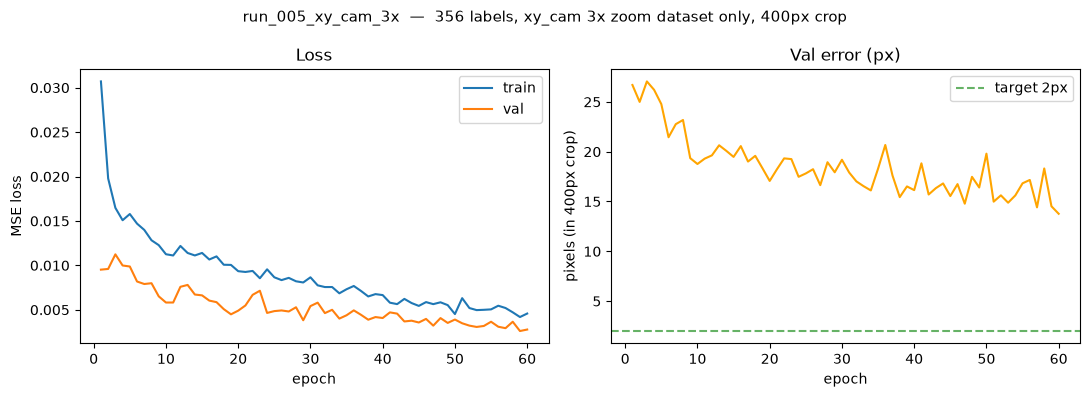

[run_005] done  elapsed=476s  val_px=13.8

Run saved to: c:\Users\zanet\repos\tcp_validator\experiments\run_005


In [13]:
import matplotlib.pyplot as plt
from experiment_tracker import Experiment

exp = Experiment({
    **config,
    "n_train": len(ds_train),
    "n_val":   len(ds_val),
}, base_dir=os.path.join(BASE, "experiments"))

opt  = torch.optim.Adam(head.parameters(), lr=config["lr"])
crit = nn.MSELoss()

# val_px: mean absolute error in crop-pixel space
# = mean_abs_normalized_error * crop_size  (not *224, which is the resized input size)
CROP = config.get("crop_size", 224)

history = {"train_loss": [], "val_loss": [], "val_px": []}

for epoch in range(1, config["epochs"] + 1):
    head.train()
    t_loss = 0
    for imgs, tgt in dl_train:
        imgs, tgt = imgs.to(DEVICE), tgt.to(DEVICE)
        with torch.no_grad():
            feats = backbone(pixel_values=imgs).last_hidden_state[:, 0, :]
        pred  = head(feats)
        loss  = crit(pred, tgt)
        opt.zero_grad(); loss.backward(); opt.step()
        t_loss += loss.item()

    head.eval()
    v_loss = v_px = 0
    with torch.no_grad():
        for imgs, tgt in dl_val:
            imgs, tgt = imgs.to(DEVICE), tgt.to(DEVICE)
            feats  = backbone(pixel_values=imgs).last_hidden_state[:, 0, :]
            pred   = head(feats)
            v_loss += crit(pred, tgt).item()
            v_px   += ((pred - tgt).abs().mean() * CROP).item()

    metrics = {
        "train_loss": t_loss / len(dl_train),
        "val_loss":   v_loss / len(dl_val),
        "val_px":     v_px   / len(dl_val),
    }
    for k, v in metrics.items():
        history[k].append(v)

    if epoch % 5 == 0 or epoch == 1:
        exp.log(epoch, metrics)

exp.save_model(head, "dinov2_head.pt")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle(f'{config["name"]}  —  {config["note"]}', fontsize=11)
epochs_x = range(1, config["epochs"] + 1)
ax1.plot(epochs_x, history["train_loss"], label="train")
ax1.plot(epochs_x, history["val_loss"],   label="val")
ax1.set_xlabel("epoch"); ax1.set_ylabel("MSE loss")
ax1.set_title("Loss"); ax1.legend()
ax2.plot(epochs_x, history["val_px"], color="orange")
ax2.axhline(2.0, color='green', linestyle='--', alpha=0.6, label='target 2px')
ax2.set_xlabel("epoch"); ax2.set_ylabel(f"pixels (in {CROP}px crop)")
ax2.set_title("Val error (px)"); ax2.legend()
plt.tight_layout()
plt.savefig(exp.run_dir / "curves.png", dpi=120)
plt.show()

exp.finish()
print(f'\nRun saved to: {exp.run_dir}')

---
## Alternative strategies to try

### Models on HuggingFace
| Model | Notes | Link |
|-------|-------|------|
| `facebook/dinov2-small` | **Top pick** — frozen backbone + regression head, <2px MAE from ~50 images | https://huggingface.co/facebook/dinov2-small |
| `usyd-community/vitpose-plus-small` | ViTPose+ Small (33M params), Transformers-compatible keypoint model | https://huggingface.co/usyd-community/vitpose-plus-small |
| `M-Hamdy/SurgBox-RT-DETR-L` | RT-DETR trained on surgical instruments, best domain-adjacent start | https://huggingface.co/M-Hamdy/SurgBox-RT-DETR-L |

### Datasets on HuggingFace
| Dataset | Notes | Link |
|---------|-------|------|
| `Voxel51/mvtec-ad` | Industrial anomaly (screws, metal nuts — circular features) | https://huggingface.co/datasets/Voxel51/mvtec-ad |

### Other approaches
| Approach | Notes | Link |
|----------|-------|------|
| YOLOv8-pose | Single-keypoint via `kpt_shape: [1, 3]`, 3.3M params, needs bounding box annotations | https://docs.ultralytics.com/tasks/pose/ |
| Anomalib / AnomalyDINO | One-shot bore anomaly detection, no training needed | https://github.com/openvinotoolkit/anomalib |
| SAM-Med2D | Point-prompted segmentation, fine-tune decoder only | https://github.com/uni-medical/SAM-Med2D |
| RTMPose | Fastest CPU inference (~300 FPS), heavy MMPose framework | https://github.com/open-mmlab/mmpose/tree/main/projects/rtmpose |

### Key papers
| Paper | Finding |
|-------|---------|
| arXiv 2604.16758 | Frozen ViT + heatmap decoder: <2px MAE from **48 images** |
| arXiv 2409.13668 | Custom regression CNN for visual servo: <2px at 400 images |
| arXiv 2308.14477 | 606-image optical needle tip detection dataset |

### Annotation tools
- **Roboflow** — easiest AI-assisted single-keypoint labeling: https://roboflow.com
- **CVAT** — open-source self-hosted: https://cvat.ai

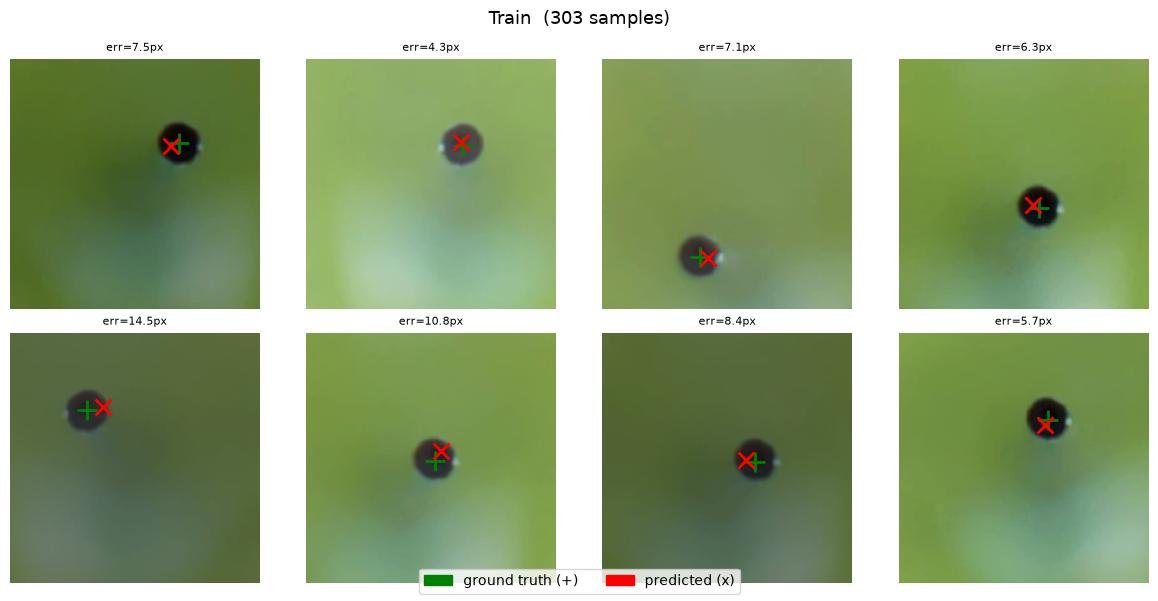

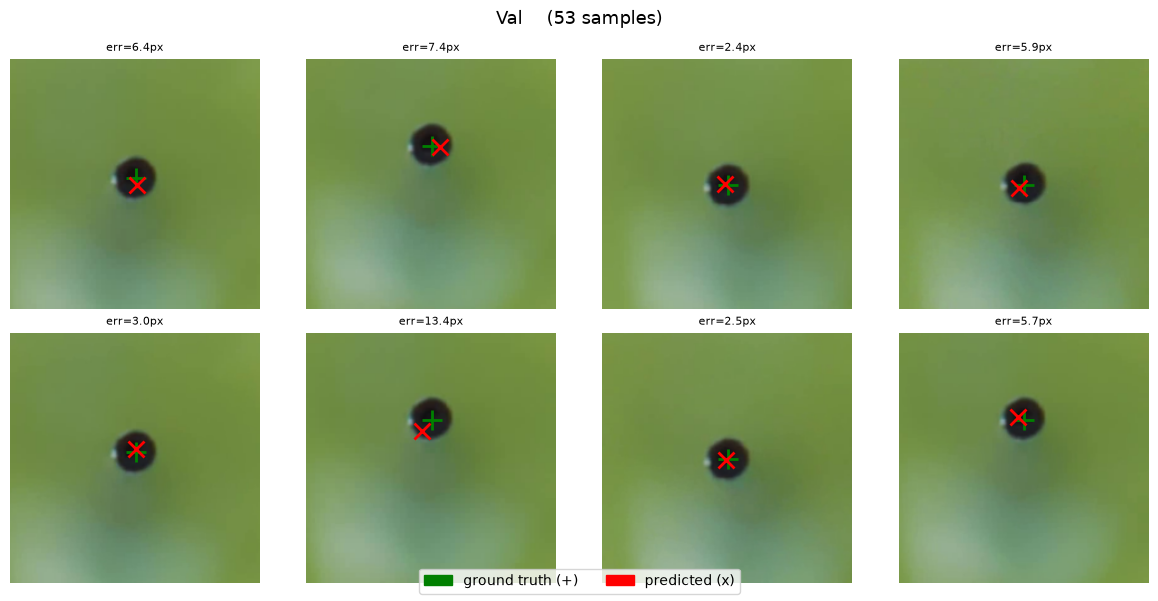

In [14]:
import matplotlib.patches as mpatches

_mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
_std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

def _denorm(t):
    return (t.cpu() * _std + _mean).clamp(0, 1).permute(1, 2, 0).numpy()

def show_predictions(loader, label, n=8, save_path=None):
    head.eval()
    imgs_out, preds_out, gts_out = [], [], []
    with torch.no_grad():
        for imgs, tgt in loader:
            feats = backbone(pixel_values=imgs.to(DEVICE)).last_hidden_state[:, 0, :]
            pred  = head(feats).cpu()
            for i in range(len(imgs)):
                imgs_out.append(imgs[i])
                preds_out.append(pred[i])
                gts_out.append(tgt[i])
                if len(imgs_out) >= n:
                    break
            if len(imgs_out) >= n:
                break

    cols = min(n, 4)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
    axes = list(axes.flat) if hasattr(axes, 'flat') else [axes]
    fig.suptitle(label, fontsize=13)

    for ax, img_t, pred_t, gt_t in zip(axes, imgs_out, preds_out, gts_out):
        img_np = _denorm(img_t)
        ax.imshow(img_np)
        H, W = img_np.shape[:2]
        gx, gy = gt_t[0].item() * W,  gt_t[1].item() * H
        px, py = pred_t[0].item() * W, pred_t[1].item() * H
        err_px = ((gx - px)**2 + (gy - py)**2) ** 0.5
        ax.plot(gx, gy, 'g+', ms=14, mew=2)
        ax.plot(px, py, 'rx', ms=12, mew=2)
        ax.set_title(f"err={err_px:.1f}px", fontsize=8)
        ax.axis('off')

    for ax in axes[len(imgs_out):]:
        ax.axis('off')

    gt_patch   = mpatches.Patch(color='green', label='ground truth (+)')
    pred_patch = mpatches.Patch(color='red',   label='predicted (x)')
    fig.legend(handles=[gt_patch, pred_patch], loc='lower center', ncol=2)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120)
    plt.show()

show_predictions(dl_train, f"Train  ({len(ds_train)} samples)", save_path=exp.run_dir / "train_samples.png")
show_predictions(dl_val,   f"Val    ({len(ds_val)} samples)",   save_path=exp.run_dir / "val_samples.png")

In [ ]:
import cv2

# ── Hough parameters — tweak if circles aren't detected ──────────────────────
HOUGH_DP        = 1       # inverse ratio of accumulator resolution to image resolution
HOUGH_MIN_DIST  = 30      # min distance between circle centers (px)
HOUGH_PARAM1    = 60      # Canny high threshold
HOUGH_PARAM2    = 20      # accumulator threshold — lower = more (false) detections
HOUGH_MIN_R     = 8       # min circle radius (px) in 224px image
HOUGH_MAX_R     = 60      # max circle radius (px) in 224px image
# ─────────────────────────────────────────────────────────────────────────────

def hough_center(img_tensor):
    """Return (cx, cy) of best Hough circle in a 224px denormalized tensor, or None."""
    img_np = (_denorm(img_tensor) * 255).astype("uint8")
    gray   = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    blur   = cv2.GaussianBlur(gray, (5, 5), 1.5)
    circles = cv2.HoughCircles(
        blur, cv2.HOUGH_GRADIENT,
        dp=HOUGH_DP, minDist=HOUGH_MIN_DIST,
        param1=HOUGH_PARAM1, param2=HOUGH_PARAM2,
        minRadius=HOUGH_MIN_R, maxRadius=HOUGH_MAX_R,
    )
    if circles is None:
        return None
    # Pick the circle whose center is closest to image center (bore is near center of crop)
    # reshape: OpenCV 4 returns (1,N,3), OpenCV 5 returns (N,3)
    H, W = img_np.shape[:2]
    best = min(circles.reshape(-1, 3), key=lambda c: (c[0] - W/2)**2 + (c[1] - H/2)**2)
    return float(best[0]), float(best[1])  # (x, y) in 224px space


def compare_hough_vs_model(loader, label, n=8, save_path=None):
    head.eval()
    imgs_out, preds_out, gts_out, houghs_out = [], [], [], []
    with torch.no_grad():
        for imgs, tgt in loader:
            feats = backbone(pixel_values=imgs.to(DEVICE)).last_hidden_state[:, 0, :]
            pred  = head(feats).cpu()
            for i in range(len(imgs)):
                hc = hough_center(imgs[i])
                imgs_out.append(imgs[i])
                preds_out.append(pred[i])
                gts_out.append(tgt[i])
                houghs_out.append(hc)
                if len(imgs_out) >= n: break
            if len(imgs_out) >= n: break

    cols = min(n, 4)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.2, rows * 3.4))
    axes = list(axes.flat) if hasattr(axes, 'flat') else [axes]
    fig.suptitle(f"{label} — model (red ×) vs Hough (blue ○) vs GT (green +)", fontsize=11)

    for ax, img_t, pred_t, gt_t, hc in zip(axes, imgs_out, preds_out, gts_out, houghs_out):
        img_np = _denorm(img_t)
        ax.imshow(img_np)
        H, W = img_np.shape[:2]

        gx,  gy  = gt_t[0].item()   * W, gt_t[1].item()   * H
        px,  py  = pred_t[0].item() * W, pred_t[1].item() * H
        model_err = ((gx - px)**2 + (gy - py)**2) ** 0.5

        ax.plot(gx, gy, 'g+', ms=14, mew=2)
        ax.plot(px, py, 'rx', ms=12, mew=2)

        if hc is not None:
            hx, hy = hc
            hough_err = ((gx - hx)**2 + (gy - hy)**2) ** 0.5
            ax.plot(hx, hy, 'bo', ms=8, mew=2, fillstyle='none')
            title = f"model={model_err:.1f}px  hough={hough_err:.1f}px"
        else:
            title = f"model={model_err:.1f}px  hough=none"

        ax.set_title(title, fontsize=7.5)
        ax.axis('off')

    for ax in axes[len(imgs_out):]:
        ax.axis('off')

    import matplotlib.patches as mpatches
    patches = [
        mpatches.Patch(color='green', label='GT (+)'),
        mpatches.Patch(color='red',   label='Model (×)'),
        mpatches.Patch(color='blue',  label='Hough (○)'),
    ]
    fig.legend(handles=patches, loc='lower center', ncol=3, fontsize=9)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120)
    plt.show()


compare_hough_vs_model(dl_val, f"Val ({len(ds_val)} samples)",
                       save_path=exp.run_dir / "hough_comparison.png")

---
## YZ-Cam — Hough Line Detection (needle side profile)
The yz camera sees the needle from the side: a thin vertical rod.  
`HoughLinesP` finds the left and right edges; their midpoint gives the needle's x-position in that view.

In [ ]:
import cv2, glob, random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ── Hough line parameters — tweak to taste ───────────────────────────────────
LINE_CANNY_LOW   = 30     # Canny lower threshold
LINE_CANNY_HIGH  = 100    # Canny upper threshold
LINE_RHO         = 1      # accumulator distance resolution (px)
LINE_THETA       = np.pi / 180   # accumulator angle resolution
LINE_THRESHOLD   = 40     # min votes to count as a line
LINE_MIN_LEN     = 40     # min segment length (px) — filters out speckle
LINE_MAX_GAP     = 15     # max gap within a segment (px)
# Near-vertical: keep lines whose angle is within this many degrees of vertical
VERTICAL_TOL_DEG = 20
# ─────────────────────────────────────────────────────────────────────────────

YZ_UNLABELED = Path(BASE) / "datasets" / "yz_cam" / "yz_cam_1x" / "unlabeled"

def detect_needle_lines(img_bgr):
    """
    Run HoughLinesP on a yz-cam frame; return (lines, needle_x) where:
      lines      — raw (x1,y1,x2,y2) segments kept after vertical filter
      needle_x   — estimated needle center x (mean of leftmost+rightmost vertical line x),
                   or None if no lines found
    """
    gray  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    blur  = cv2.GaussianBlur(gray, (5, 5), 1.0)
    edges = cv2.Canny(blur, LINE_CANNY_LOW, LINE_CANNY_HIGH)

    raw = cv2.HoughLinesP(edges, LINE_RHO, LINE_THETA, LINE_THRESHOLD,
                          minLineLength=LINE_MIN_LEN, maxLineGap=LINE_MAX_GAP)
    if raw is None:
        return [], None

    # Keep only near-vertical lines
    # reshape: OpenCV 4 returns (N,1,4), OpenCV 5 returns (N,4)
    vertical = []
    for seg in raw.reshape(-1, 4):
        x1, y1, x2, y2 = (int(v) for v in seg)
        dx, dy = abs(x2 - x1), abs(y2 - y1)
        angle_from_vertical = np.degrees(np.arctan2(dx, dy + 1e-6))
        if angle_from_vertical < VERTICAL_TOL_DEG:
            vertical.append((x1, y1, x2, y2))

    if not vertical:
        return [], None

    # Needle center x = midpoint of leftmost and rightmost vertical line
    xs = [min(s[0], s[2]) for s in vertical] + [max(s[0], s[2]) for s in vertical]
    needle_x = (min(xs) + max(xs)) / 2
    return vertical, needle_x


def show_needle_lines(n_frames=8, seed=42):
    """Sample n_frames from yz_cam and visualise Hough needle detection."""
    frames = sorted(YZ_UNLABELED.glob("*.jpg"))
    if not frames:
        print(f"No frames found in {YZ_UNLABELED}")
        return

    rng = random.Random(seed)
    chosen = rng.sample(frames, min(n_frames, len(frames)))

    cols = min(n_frames, 4)
    rows = (len(chosen) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.2))
    axes = list(axes.flat) if hasattr(axes, 'flat') else [axes]
    fig.suptitle("YZ-Cam — Hough needle lines  (green=segments, red=center x)", fontsize=11)

    detected = 0
    for ax, fpath in zip(axes, chosen):
        img_bgr = cv2.imread(str(fpath))
        if img_bgr is None:
            ax.axis('off'); continue
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        lines, needle_x = detect_needle_lines(img_bgr)

        overlay = img_rgb.copy()
        for x1, y1, x2, y2 in lines:
            cv2.line(overlay, (x1, y1), (x2, y2), (0, 220, 80), 2)

        ax.imshow(overlay)

        if needle_x is not None:
            ax.axvline(needle_x, color='red', linewidth=1.5, alpha=0.8)
            ax.set_title(f"needle_x={needle_x:.0f}px  ({len(lines)} segs)", fontsize=8)
            detected += 1
        else:
            ax.set_title("no lines detected", fontsize=8, color='orange')

        ax.axis('off')

    for ax in axes[len(chosen):]:
        ax.axis('off')

    plt.tight_layout()
    out = Path(BASE) / "experiments" / "yz_hough_lines.png"
    plt.savefig(out, dpi=120)
    plt.show()
    print(f"Detected needle in {detected}/{len(chosen)} frames  →  saved {out}")


show_needle_lines(n_frames=8)

---
## Tilted check — deployed DINOv2 head on an unlabeled tilted recording
Only needs the setup cells (imports, backbone, `BoreHead`); no retraining. Loads `models/dinov2_head.pt`, the head the servo script uses.

No hand labels exist yet, so the **green +** is the dark-blob detector, a reference rather than ground truth (it was 1px median on xy_cam_3x). Each 400px crop is centered on that point and shifted up to ±60px, the same jitter as training, so the model isn't handed the bore at dead center. Errors are in **real pixels**, not 224px thumbnail pixels.

DINOv2 bore head loaded (facebook/dinov2-small): C:\Users\zanet\repos\tcp_validator\models\dinov2_head.pt


182209: 45 frames, dark-blob reference on 45
  DINOv2 vs reference: median 84.9px   90th pct 130.8px
  Hough  vs reference: median 2.0px   (45/45 frames found a circle)


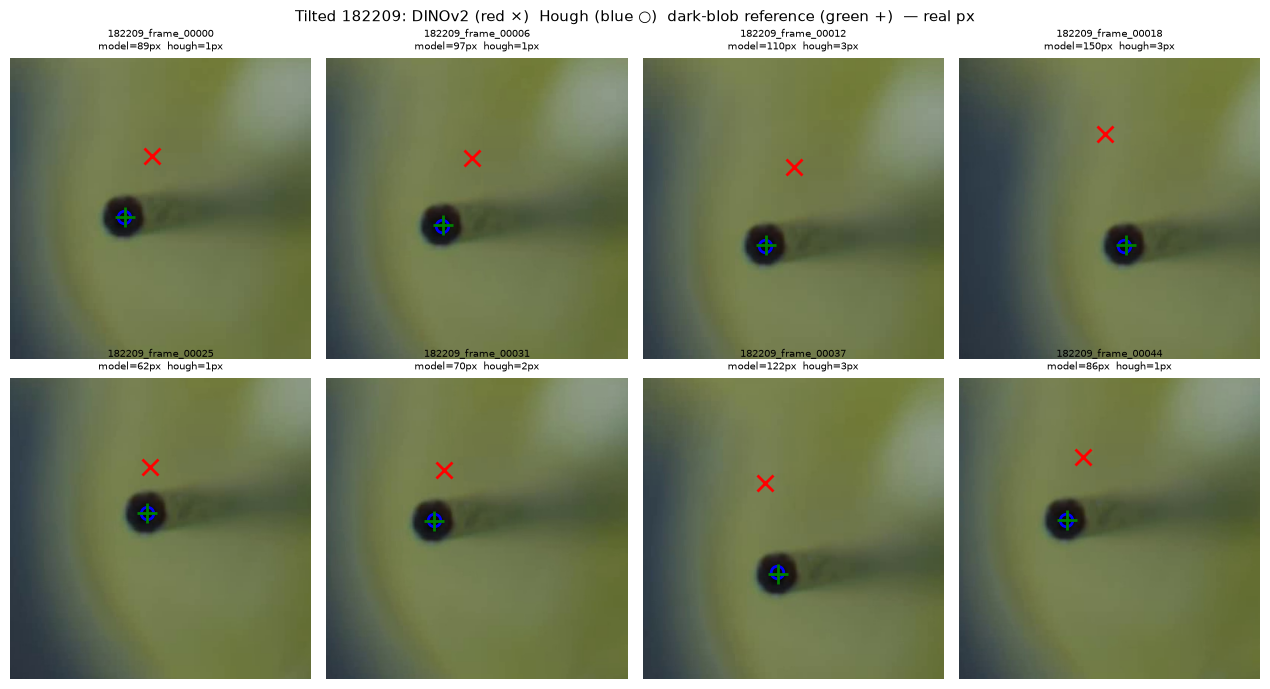

saved C:\Users\zanet\repos\tcp_validator\experiments\tilted_checks\182209.png


In [5]:
import glob, random, cv2
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision import transforms
from cv_algorithms import detect_bottom

TILT_VIDEO = "182209"   # 182022 (likely untilted), 182142, 182209, 182236 (tip on dark bg), 182302
N_SHOW     = 8
CROP       = 400
JIT        = int(0.15 * CROP)   # ±60px, same as training

deployed = BoreHead(FEAT_DIM).to(DEVICE)
deployed.load_state_dict(torch.load(os.path.join(BASE, "models", "dinov2_head.pt"), map_location=DEVICE))
deployed.eval()
_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                          transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def _hough(crop_rgb):
    """Same params as the Hough comparison cell, run on the 224px crop; returns crop-pixel coords."""
    g = cv2.GaussianBlur(cv2.cvtColor(cv2.resize(crop_rgb, (224, 224)), cv2.COLOR_RGB2GRAY), (5, 5), 1.5)
    c = cv2.HoughCircles(g, cv2.HOUGH_GRADIENT, dp=1, minDist=30, param1=60, param2=20, minRadius=8, maxRadius=60)
    if c is None:
        return None
    x, y, _ = min(c.reshape(-1, 3), key=lambda k: (k[0] - 112) ** 2 + (k[1] - 112) ** 2)
    return float(x) * CROP / 224, float(y) * CROP / 224

frames = sorted(glob.glob(os.path.join(BASE, "datasets", "xy_cam", "xy_cam_2.5x_tilted", "*", f"{TILT_VIDEO}_*.jpg")))
rng = random.Random(0)
recs = []
for p in frames:
    bgr = cv2.imread(p); H, W = bgr.shape[:2]
    ref, _, bc = detect_bottom(bgr, None)
    ref = ref if bc is not None else None            # only trust the dark-blob path as a reference
    cx, cy = ref if ref else (W // 2, H // 2)
    cx, cy = cx + rng.randint(-JIT, JIT), cy + rng.randint(-JIT, JIT)
    x1 = min(max(0, cx - CROP // 2), W - CROP)
    y1 = min(max(0, cy - CROP // 2), H - CROP)
    crop = cv2.cvtColor(bgr[y1:y1 + CROP, x1:x1 + CROP], cv2.COLOR_BGR2RGB)
    with torch.no_grad():
        feats = backbone(pixel_values=_tf(Image.fromarray(crop)).unsqueeze(0).to(DEVICE)).last_hidden_state[:, 0, :]
        pred = deployed(feats)[0].cpu().numpy() * CROP
    recs.append(dict(name=Path(p).stem, crop=crop, pred=pred, hough=_hough(crop),
                     ref=None if ref is None else (ref[0] - x1, ref[1] - y1)))

def _err(a, b):
    return float(np.hypot(a[0] - b[0], a[1] - b[1]))

m_err = [_err(r["pred"], r["ref"]) for r in recs if r["ref"]]
h_err = [_err(r["hough"], r["ref"]) for r in recs if r["ref"] and r["hough"]]
n_ref = sum(r["ref"] is not None for r in recs)
print(f"{TILT_VIDEO}: {len(recs)} frames, dark-blob reference on {n_ref}")
if m_err:
    print(f"  DINOv2 vs reference: median {np.median(m_err):.1f}px   90th pct {np.percentile(m_err, 90):.1f}px")
if h_err:
    print(f"  Hough  vs reference: median {np.median(h_err):.1f}px   ({len(h_err)}/{n_ref} frames found a circle)")

picks = [recs[i] for i in np.linspace(0, len(recs) - 1, N_SHOW).astype(int)]
fig, axes = plt.subplots(2, N_SHOW // 2, figsize=(N_SHOW // 2 * 3.2, 7))
fig.suptitle(f"Tilted {TILT_VIDEO}: DINOv2 (red ×)  Hough (blue ○)  dark-blob reference (green +)  — real px",
             fontsize=11)
for ax, r in zip(axes.flat, picks):
    ax.imshow(r["crop"]); ax.axis("off")
    ax.plot(*r["pred"], "rx", ms=12, mew=2)
    if r["hough"]:
        ax.plot(*r["hough"], "bo", ms=9, mew=2, fillstyle="none")
    if r["ref"]:
        ax.plot(*r["ref"], "g+", ms=14, mew=2)
        t = f"model={_err(r['pred'], r['ref']):.0f}px  " + (
            f"hough={_err(r['hough'], r['ref']):.0f}px" if r["hough"] else "hough=none")
    else:
        t = "no dark blob: judge by eye"
    ax.set_title(f"{r['name']}\n{t}", fontsize=7.5)
plt.tight_layout()
out_dir = Path(BASE) / "experiments" / "tilted_checks"; out_dir.mkdir(exist_ok=True)
plt.savefig(out_dir / f"{TILT_VIDEO}.png", dpi=120)
plt.show()
print(f"saved {out_dir / f'{TILT_VIDEO}.png'}")